<a href="https://colab.research.google.com/github/lizlorenzana931109-art/FinPredict-Actividad6/blob/main/nootebook/01_evaluacion_modelos_actividad6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FinPredict — Actividad 6
## Evaluación y validación de modelos de riesgo hipotecario

### Objetivo

Evaluar y comparar modelos de clasificación para identificar de forma
anticipada créditos hipotecarios con riesgo de alcanzar 90 días de
incumplimiento dentro de la siguiente ventana trimestral.

### Población objetivo

FinPredict opera sobre créditos que presentan entre 0 y 60 días de atraso
al momento del corte.

Los créditos con 61 a 89 días de atraso se consideran parte de una estrategia
de cobranza intensiva, mientras que aquellos con 90 días o más corresponden
a incumplimientos ya materializados y quedan fuera del alcance preventivo
del modelo.

### Variable objetivo

`incumplimiento_90d`

Indica si el crédito mantiene saldo materialmente pendiente cuando alguna
obligación alcanza 90 días de atraso dentro de la ventana futura de predicción.

### Estrategia de evaluación

Se utilizarán tres niveles de comparación:

1. DummyClassifier como línea base.
2. Regresión Logística como modelo interpretable.
3. Random Forest como modelo no lineal.

Debido al desbalance de clases, la selección del modelo no se realizará
únicamente mediante accuracy. Se analizarán Precision, Recall, F1-score,
Specificity, ROC-AUC, PR-AUC y matrices de confusión.

La selección y ajuste se realizarán exclusivamente sobre el conjunto de
desarrollo mediante validación temporal. El conjunto de evaluación final
permanecerá reservado hasta el cierre del proceso de selección.

In [3]:
# ============================================================
# FINPREDICT | ACTIVIDAD 6
# 1. CARGA DIRECTA DESDE GITHUB
# ============================================================

import pandas as pd

URL_BASE = (
    "https://raw.githubusercontent.com/"
    "lizlorenzana931109-art/"
    "FinPredict-Actividad6/"
    "main/Data/"
)

URL_DESARROLLO = URL_BASE + "finpredict_desarrollo_v2.parquet"
URL_EVALUACION = URL_BASE + "finpredict_evaluacion_v2.parquet"

df_desarrollo = pd.read_parquet(URL_DESARROLLO)
df_evaluacion = pd.read_parquet(URL_EVALUACION)

print("FINPREDICT | ACTIVIDAD 6")
print("-" * 60)

print(
    f"Desarrollo: "
    f"{df_desarrollo.shape[0]:,} observaciones | "
    f"{df_desarrollo.shape[1]} variables"
)

print(
    f"Evaluación final: "
    f"{df_evaluacion.shape[0]:,} observaciones | "
    f"{df_evaluacion.shape[1]} variables"
)

print("-" * 60)
print("Datos V2 cargados directamente desde GitHub.")

FINPREDICT | ACTIVIDAD 6
------------------------------------------------------------
Desarrollo: 303,234 observaciones | 30 variables
Evaluación final: 33,603 observaciones | 30 variables
------------------------------------------------------------
Datos V2 cargados directamente desde GitHub.


In [4]:
# ============================================================
# FINPREDICT | ACTIVIDAD 6
# 2. CLASIFICACIÓN DE VARIABLES
# ============================================================

# ------------------------------------------------------------
# 1. Columnas de control
# ------------------------------------------------------------

COLUMNAS_CONTROL = [
    "id_credito",
    "id_ventana",
    "fecha_corte",
    "inicio_prediccion",
    "fin_prediccion",
    "uso",
    "fecha_apertura"
]

# ------------------------------------------------------------
# 2. Variable objetivo
# ------------------------------------------------------------

COLUMNA_TARGET = "incumplimiento_90d"

# ------------------------------------------------------------
# 3. Predictores del modelo
# ------------------------------------------------------------

COLUMNAS_PREDICTORAS = [
    "monto_original",
    "plazo_meses",
    "tasa_interes_anual",
    "pago_mensual",
    "ingreso_mensual",
    "antiguedad_meses",
    "saldo_vencido",
    "dias_atraso",
    "relacion_pago_ingreso",
    "saldo_vencido_mensualidades",
    "importe_pagado_3m",
    "numero_pagos_3m",
    "importe_exigible_3m",
    "obligaciones_3m",
    "porcentaje_pago_3m"
]

# ------------------------------------------------------------
# 4. Variables de auditoría / análisis de negocio
# ------------------------------------------------------------

COLUMNAS_AUDITORIA = [
    "mora_90_corte",
    "tipo_empleo",
    "edad",
    "region",
    "pagos_parciales_3m",
    "regularizaciones_3m",
    "categoria_cobertura_3m"
]

# ------------------------------------------------------------
# 5. Validar cobertura de columnas
# ------------------------------------------------------------

columnas_clasificadas = (
    COLUMNAS_CONTROL
    + [COLUMNA_TARGET]
    + COLUMNAS_PREDICTORAS
    + COLUMNAS_AUDITORIA
)

faltantes = set(df_desarrollo.columns) - set(columnas_clasificadas)
inexistentes = set(columnas_clasificadas) - set(df_desarrollo.columns)

assert not faltantes, f"Columnas sin clasificar: {faltantes}"
assert not inexistentes, f"Columnas inexistentes: {inexistentes}"

assert len(columnas_clasificadas) == len(set(columnas_clasificadas))

print("FINPREDICT | CLASIFICACIÓN DE VARIABLES")
print("-" * 65)

print(f"Variables totales: {len(df_desarrollo.columns)}")
print(f"Predictores: {len(COLUMNAS_PREDICTORAS)}")
print(f"Control: {len(COLUMNAS_CONTROL)}")
print(f"Auditoría: {len(COLUMNAS_AUDITORIA)}")
print(f"Target: {COLUMNA_TARGET}")

print("-" * 65)
print("Clasificación validada correctamente.")

FINPREDICT | CLASIFICACIÓN DE VARIABLES
-----------------------------------------------------------------
Variables totales: 30
Predictores: 15
Control: 7
Auditoría: 7
Target: incumplimiento_90d
-----------------------------------------------------------------
Clasificación validada correctamente.


In [5]:
# ============================================================
# FINPREDICT | ACTIVIDAD 6
# 3. AUDITORÍA DE DESARROLLO VS EVALUACIÓN FINAL
# ============================================================

def resumen_dataset(df, nombre):

    return {
        "dataset": nombre,
        "observaciones": len(df),
        "creditos_distintos": df["id_credito"].nunique(),
        "incumplimientos": int(df[COLUMNA_TARGET].sum()),
        "prevalencia_%": round(
            df[COLUMNA_TARGET].mean() * 100,
            2
        ),
        "nulos_totales": int(df.isna().sum().sum()),
        "duplicados_credito_corte": int(
            df.duplicated(
                ["id_credito", "fecha_corte"]
            ).sum()
        ),
        "fecha_corte_min": df["fecha_corte"].min(),
        "fecha_corte_max": df["fecha_corte"].max()
    }


resumen_split = pd.DataFrame([
    resumen_dataset(
        df_desarrollo,
        "Desarrollo"
    ),
    resumen_dataset(
        df_evaluacion,
        "Evaluación final"
    )
])

print("FINPREDICT | AUDITORÍA DEL SPLIT TEMPORAL")
print("-" * 75)

display(resumen_split)

# ------------------------------------------------------------
# Validaciones
# ------------------------------------------------------------

assert df_desarrollo.isna().sum().sum() == 0
assert df_evaluacion.isna().sum().sum() == 0

assert not df_desarrollo.duplicated(
    ["id_credito", "fecha_corte"]
).any()

assert not df_evaluacion.duplicated(
    ["id_credito", "fecha_corte"]
).any()

assert (
    df_desarrollo["fecha_corte"].max()
    < df_evaluacion["fecha_corte"].min()
)

print("-" * 75)
print("Split temporal validado correctamente.")

FINPREDICT | AUDITORÍA DEL SPLIT TEMPORAL
---------------------------------------------------------------------------


,dataset,observaciones,creditos_distintos,incumplimientos,prevalencia_%,nulos_totales,duplicados_credito_corte,fecha_corte_min,fecha_corte_max
0,Desarrollo,303234,42036,11642,3.84,0,0,2021-06-30,2025-06-30
1,Evaluación final,33603,33603,1256,3.74,0,0,2025-09-30,2025-09-30


---------------------------------------------------------------------------
Split temporal validado correctamente.


In [6]:
# ============================================================
# FINPREDICT | ACTIVIDAD 6
# 4. BASELINE CON DUMMYCLASSIFIER
# ============================================================

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Variables de desarrollo
# ------------------------------------------------------------

X_desarrollo = df_desarrollo[COLUMNAS_PREDICTORAS].copy()
y_desarrollo = df_desarrollo[COLUMNA_TARGET].copy()

# ------------------------------------------------------------
# 2. Baseline
# ------------------------------------------------------------

dummy = DummyClassifier(
    strategy="most_frequent"
)

dummy.fit(
    X_desarrollo,
    y_desarrollo
)

# ------------------------------------------------------------
# 3. Predicciones sobre desarrollo
# ------------------------------------------------------------

y_pred_dummy = dummy.predict(
    X_desarrollo
)

y_prob_dummy = dummy.predict_proba(
    X_desarrollo
)[:, 1]

# ------------------------------------------------------------
# 4. Métricas
# ------------------------------------------------------------

tn, fp, fn, tp = confusion_matrix(
    y_desarrollo,
    y_pred_dummy
).ravel()

specificity_dummy = (
    tn / (tn + fp)
)

metricas_dummy = pd.DataFrame({
    "modelo": ["DummyClassifier"],
    "accuracy": [
        accuracy_score(
            y_desarrollo,
            y_pred_dummy
        )
    ],
    "precision": [
        precision_score(
            y_desarrollo,
            y_pred_dummy,
            zero_division=0
        )
    ],
    "recall": [
        recall_score(
            y_desarrollo,
            y_pred_dummy,
            zero_division=0
        )
    ],
    "specificity": [
        specificity_dummy
    ],
    "f1": [
        f1_score(
            y_desarrollo,
            y_pred_dummy,
            zero_division=0
        )
    ],
    "roc_auc": [
        roc_auc_score(
            y_desarrollo,
            y_prob_dummy
        )
    ],
    "pr_auc": [
        average_precision_score(
            y_desarrollo,
            y_prob_dummy
        )
    ]
})

# ------------------------------------------------------------
# 5. Resultados
# ------------------------------------------------------------

print("FINPREDICT | BASELINE")
print("-" * 70)

display(
    metricas_dummy.round(4)
)

print("\nMatriz de confusión:")
print(
    confusion_matrix(
        y_desarrollo,
        y_pred_dummy
    )
)

print("-" * 70)

FINPREDICT | BASELINE
----------------------------------------------------------------------


,modelo,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc
0,DummyClassifier,0.9616,0.0,0.0,1.0,0.0,0.5,0.0384



Matriz de confusión:
[[291592      0]
 [ 11642      0]]
----------------------------------------------------------------------


In [7]:
# ============================================================
# FINPREDICT | ACTIVIDAD 6
# 5. REGRESIÓN LOGÍSTICA
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# ------------------------------------------------------------
# 1. Pipeline
# ------------------------------------------------------------

pipeline_logistica = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "modelo",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=SEED
        )
    )
])

# ------------------------------------------------------------
# 2. Entrenamiento
# ------------------------------------------------------------

pipeline_logistica.fit(
    X_desarrollo,
    y_desarrollo
)

# ------------------------------------------------------------
# 3. Predicciones
# ------------------------------------------------------------

y_pred_logistica = pipeline_logistica.predict(
    X_desarrollo
)

y_prob_logistica = pipeline_logistica.predict_proba(
    X_desarrollo
)[:, 1]

# ------------------------------------------------------------
# 4. Métricas
# ------------------------------------------------------------

tn, fp, fn, tp = confusion_matrix(
    y_desarrollo,
    y_pred_logistica
).ravel()

specificity_logistica = (
    tn / (tn + fp)
)

metricas_logistica = pd.DataFrame({
    "modelo": ["Regresión Logística"],
    "accuracy": [
        accuracy_score(
            y_desarrollo,
            y_pred_logistica
        )
    ],
    "precision": [
        precision_score(
            y_desarrollo,
            y_pred_logistica,
            zero_division=0
        )
    ],
    "recall": [
        recall_score(
            y_desarrollo,
            y_pred_logistica,
            zero_division=0
        )
    ],
    "specificity": [
        specificity_logistica
    ],
    "f1": [
        f1_score(
            y_desarrollo,
            y_pred_logistica,
            zero_division=0
        )
    ],
    "roc_auc": [
        roc_auc_score(
            y_desarrollo,
            y_prob_logistica
        )
    ],
    "pr_auc": [
        average_precision_score(
            y_desarrollo,
            y_prob_logistica
        )
    ]
})

# ------------------------------------------------------------
# 5. Comparación preliminar
# ------------------------------------------------------------

comparacion_inicial = pd.concat(
    [
        metricas_dummy,
        metricas_logistica
    ],
    ignore_index=True
)

print("FINPREDICT | COMPARACIÓN INICIAL")
print("-" * 75)

display(
    comparacion_inicial.round(4)
)

print("\nMatriz de confusión - Regresión Logística:")

print(
    confusion_matrix(
        y_desarrollo,
        y_pred_logistica
    )
)

FINPREDICT | COMPARACIÓN INICIAL
---------------------------------------------------------------------------


,modelo,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc
0,DummyClassifier,0.9616,0.0000,0.0000,1.0000,0.0000,0.500,0.0384
1,Regresión Logística,0.8613,0.1976,0.8532,0.8617,0.3209,0.925,0.3405



Matriz de confusión - Regresión Logística:
[[251251  40341]
 [  1709   9933]]


In [8]:
# ============================================================
# FINPREDICT | ACTIVIDAD 6
# 6. RANDOM FOREST
# ============================================================

from sklearn.ensemble import RandomForestClassifier

# ------------------------------------------------------------
# 1. Modelo
# ------------------------------------------------------------

modelo_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

# ------------------------------------------------------------
# 2. Entrenamiento
# ------------------------------------------------------------

modelo_rf.fit(
    X_desarrollo,
    y_desarrollo
)

# ------------------------------------------------------------
# 3. Predicciones
# ------------------------------------------------------------

y_pred_rf = modelo_rf.predict(
    X_desarrollo
)

y_prob_rf = modelo_rf.predict_proba(
    X_desarrollo
)[:, 1]

# ------------------------------------------------------------
# 4. Matriz de confusión
# ------------------------------------------------------------

tn, fp, fn, tp = confusion_matrix(
    y_desarrollo,
    y_pred_rf
).ravel()

specificity_rf = (
    tn / (tn + fp)
)

# ------------------------------------------------------------
# 5. Métricas
# ------------------------------------------------------------

metricas_rf = pd.DataFrame({
    "modelo": ["Random Forest"],

    "accuracy": [
        accuracy_score(
            y_desarrollo,
            y_pred_rf
        )
    ],

    "precision": [
        precision_score(
            y_desarrollo,
            y_pred_rf,
            zero_division=0
        )
    ],

    "recall": [
        recall_score(
            y_desarrollo,
            y_pred_rf,
            zero_division=0
        )
    ],

    "specificity": [
        specificity_rf
    ],

    "f1": [
        f1_score(
            y_desarrollo,
            y_pred_rf,
            zero_division=0
        )
    ],

    "roc_auc": [
        roc_auc_score(
            y_desarrollo,
            y_prob_rf
        )
    ],

    "pr_auc": [
        average_precision_score(
            y_desarrollo,
            y_prob_rf
        )
    ]
})

# ------------------------------------------------------------
# 6. Comparación preliminar
# ------------------------------------------------------------

comparacion_modelos = pd.concat(
    [
        metricas_dummy,
        metricas_logistica,
        metricas_rf
    ],
    ignore_index=True
)

print("FINPREDICT | COMPARACIÓN DE MODELOS")
print("-" * 80)

display(
    comparacion_modelos.round(4)
)

print("\nMatriz de confusión - Random Forest:")

print(
    confusion_matrix(
        y_desarrollo,
        y_pred_rf
    )
)

FINPREDICT | COMPARACIÓN DE MODELOS
--------------------------------------------------------------------------------


,modelo,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc
0,DummyClassifier,0.9616,0.0000,0.0000,1.0000,0.0000,0.500,0.0384
1,Regresión Logística,0.8613,0.1976,0.8532,0.8617,0.3209,0.925,0.3405
2,Random Forest,0.8765,0.2210,0.8779,0.8765,0.3531,0.952,0.4691



Matriz de confusión - Random Forest:
[[255571  36021]
 [  1422  10220]]


In [9]:
# ============================================================
# FINPREDICT | ACTIVIDAD 6
# 7. DEFINICIÓN DE VALIDACIÓN CRUZADA TEMPORAL
# ============================================================

# Ventanas históricas disponibles
ventanas_historicas = sorted(
    df_desarrollo["id_ventana"].unique()
)

print("Ventanas históricas disponibles:")
print(ventanas_historicas)

# ------------------------------------------------------------
# Folds temporales expansivos
# ------------------------------------------------------------

folds_temporales = [
    {
        "fold": 1,
        "train": list(range(2, 10)),
        "valid": [10, 11]
    },
    {
        "fold": 2,
        "train": list(range(2, 12)),
        "valid": [12, 13]
    },
    {
        "fold": 3,
        "train": list(range(2, 14)),
        "valid": [14, 15]
    }
]

resumen_folds = []

for config in folds_temporales:

    train_mask = df_desarrollo[
        "id_ventana"
    ].isin(config["train"])

    valid_mask = df_desarrollo[
        "id_ventana"
    ].isin(config["valid"])

    resumen_folds.append({
        "fold": config["fold"],
        "train_ventanas": (
            f"{min(config['train'])}-{max(config['train'])}"
        ),
        "valid_ventanas": (
            f"{min(config['valid'])}-{max(config['valid'])}"
        ),
        "train_observaciones": int(train_mask.sum()),
        "valid_observaciones": int(valid_mask.sum()),
        "train_prevalencia_%": round(
            df_desarrollo.loc[
                train_mask,
                COLUMNA_TARGET
            ].mean() * 100,
            2
        ),
        "valid_prevalencia_%": round(
            df_desarrollo.loc[
                valid_mask,
                COLUMNA_TARGET
            ].mean() * 100,
            2
        )
    })

df_resumen_folds = pd.DataFrame(
    resumen_folds
)

print("\nFINPREDICT | FOLDS TEMPORALES")
print("-" * 80)

display(df_resumen_folds)

Ventanas históricas disponibles:
[np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18)]

FINPREDICT | FOLDS TEMPORALES
--------------------------------------------------------------------------------


,fold,train_ventanas,valid_ventanas,train_observaciones,valid_observaciones,train_prevalencia_%,valid_prevalencia_%
0,1,2-9,10-11,77124,37755,3.83,3.87
1,2,2-11,12-13,114879,45081,3.84,4.05
2,3,2-13,14-15,159960,51913,3.90,3.80


In [10]:
# ============================================================
# FINPREDICT | ACTIVIDAD 6
# 8. VALIDACIÓN CRUZADA TEMPORAL
# ============================================================

from sklearn.base import clone

resultados_cv = []

for config in folds_temporales:

    fold = config["fold"]

    # --------------------------------------------------------
    # 1. Separación temporal
    # --------------------------------------------------------

    train_mask = df_desarrollo[
        "id_ventana"
    ].isin(config["train"])

    valid_mask = df_desarrollo[
        "id_ventana"
    ].isin(config["valid"])

    X_train = df_desarrollo.loc[
        train_mask,
        COLUMNAS_PREDICTORAS
    ]

    y_train = df_desarrollo.loc[
        train_mask,
        COLUMNA_TARGET
    ]

    X_valid = df_desarrollo.loc[
        valid_mask,
        COLUMNAS_PREDICTORAS
    ]

    y_valid = df_desarrollo.loc[
        valid_mask,
        COLUMNA_TARGET
    ]

    # --------------------------------------------------------
    # 2. Modelos
    # --------------------------------------------------------

    modelos_cv = {
        "Regresión Logística": clone(
            pipeline_logistica
        ),
        "Random Forest": clone(
            modelo_rf
        )
    }

    # --------------------------------------------------------
    # 3. Entrenamiento y evaluación
    # --------------------------------------------------------

    for nombre_modelo, modelo in modelos_cv.items():

        modelo.fit(
            X_train,
            y_train
        )

        y_pred = modelo.predict(
            X_valid
        )

        y_prob = modelo.predict_proba(
            X_valid
        )[:, 1]

        tn, fp, fn, tp = confusion_matrix(
            y_valid,
            y_pred
        ).ravel()

        specificity = (
            tn / (tn + fp)
        )

        resultados_cv.append({

            "fold": fold,
            "modelo": nombre_modelo,

            "train_obs": len(X_train),
            "valid_obs": len(X_valid),

            "accuracy": accuracy_score(
                y_valid,
                y_pred
            ),

            "precision": precision_score(
                y_valid,
                y_pred,
                zero_division=0
            ),

            "recall": recall_score(
                y_valid,
                y_pred,
                zero_division=0
            ),

            "specificity": specificity,

            "f1": f1_score(
                y_valid,
                y_pred,
                zero_division=0
            ),

            "roc_auc": roc_auc_score(
                y_valid,
                y_prob
            ),

            "pr_auc": average_precision_score(
                y_valid,
                y_prob
            ),

            "tn": tn,
            "fp": fp,
            "fn": fn,
            "tp": tp
        })

# ------------------------------------------------------------
# 4. Resultados por fold
# ------------------------------------------------------------

df_resultados_cv = pd.DataFrame(
    resultados_cv
)

print("FINPREDICT | VALIDACIÓN CRUZADA TEMPORAL")
print("-" * 90)

display(
    df_resultados_cv[
        [
            "fold",
            "modelo",
            "precision",
            "recall",
            "specificity",
            "f1",
            "roc_auc",
            "pr_auc"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 5. Media y desviación estándar
# ------------------------------------------------------------

resumen_cv = (
    df_resultados_cv
    .groupby("modelo")[
        [
            "precision",
            "recall",
            "specificity",
            "f1",
            "roc_auc",
            "pr_auc"
        ]
    ]
    .agg(
        ["mean", "std"]
    )
    .round(4)
)

print("\nRESUMEN CV | MEDIA ± DESVIACIÓN ESTÁNDAR")
print("-" * 90)

display(resumen_cv)

FINPREDICT | VALIDACIÓN CRUZADA TEMPORAL
------------------------------------------------------------------------------------------


,fold,modelo,precision,recall,specificity,f1,roc_auc,pr_auc
0,1,Regresión Logística,0.1957,0.8493,0.8596,0.3181,0.9205,0.3391
1,1,Random Forest,0.2167,0.8130,0.8818,0.3422,0.9183,0.3302
2,2,Regresión Logística,0.2124,0.8506,0.8668,0.3399,0.9258,0.3643
3,2,Random Forest,0.2354,0.8254,0.8868,0.3663,0.9256,0.3518
4,3,Regresión Logística,0.1927,0.8529,0.8589,0.3144,0.9218,0.3193
5,3,Random Forest,0.2075,0.8301,0.8748,0.3320,0.9219,0.3135



RESUMEN CV | MEDIA ± DESVIACIÓN ESTÁNDAR
------------------------------------------------------------------------------------------


precision          recall         specificity          \
                         mean     std    mean     std        mean     std   
modelo                                                                      
Random Forest          0.2199  0.0142  0.8228  0.0088      0.8811  0.0060   
Regresión Logística    0.2003  0.0106  0.8509  0.0018      0.8617  0.0044   

                         f1         roc_auc          pr_auc          
                       mean     std    mean     std    mean     std  
modelo                                                               
Random Forest        0.3468  0.0176  0.9219  0.0037  0.3318  0.0192  
Regresión Logística  0.3241  0.0138  0.9227  0.0027  0.3409  0.0225

In [11]:
# ============================================================
# FINPREDICT | ACTIVIDAD 6
# 9. PREDICCIONES OUT-OF-FOLD PARA COMPARACIÓN ESTADÍSTICA
# ============================================================

from sklearn.base import clone

predicciones_oof = []

for config in folds_temporales:

    fold = config["fold"]

    # --------------------------------------------------------
    # 1. Separación temporal
    # --------------------------------------------------------

    train_mask = df_desarrollo[
        "id_ventana"
    ].isin(config["train"])

    valid_mask = df_desarrollo[
        "id_ventana"
    ].isin(config["valid"])

    X_train = df_desarrollo.loc[
        train_mask,
        COLUMNAS_PREDICTORAS
    ]

    y_train = df_desarrollo.loc[
        train_mask,
        COLUMNA_TARGET
    ]

    X_valid = df_desarrollo.loc[
        valid_mask,
        COLUMNAS_PREDICTORAS
    ]

    y_valid = df_desarrollo.loc[
        valid_mask,
        COLUMNA_TARGET
    ]

    # Identificadores de las observaciones de validación
    info_valid = df_desarrollo.loc[
        valid_mask,
        [
            "id_credito",
            "id_ventana",
            "fecha_corte"
        ]
    ].copy()

    # --------------------------------------------------------
    # 2. Regresión Logística
    # --------------------------------------------------------

    modelo_log_oof = clone(
        pipeline_logistica
    )

    modelo_log_oof.fit(
        X_train,
        y_train
    )

    prob_log = modelo_log_oof.predict_proba(
        X_valid
    )[:, 1]

    # --------------------------------------------------------
    # 3. Random Forest
    # --------------------------------------------------------

    modelo_rf_oof = clone(
        modelo_rf
    )

    modelo_rf_oof.fit(
        X_train,
        y_train
    )

    prob_rf = modelo_rf_oof.predict_proba(
        X_valid
    )[:, 1]

    # --------------------------------------------------------
    # 4. Consolidar predicciones
    # --------------------------------------------------------

    resultado_fold = info_valid.copy()

    resultado_fold["fold"] = fold

    resultado_fold[
        "incumplimiento_90d"
    ] = y_valid.values

    resultado_fold[
        "prob_logistica"
    ] = prob_log

    resultado_fold[
        "prob_random_forest"
    ] = prob_rf

    predicciones_oof.append(
        resultado_fold
    )

# ------------------------------------------------------------
# 5. Base OOF
# ------------------------------------------------------------

df_oof = pd.concat(
    predicciones_oof,
    ignore_index=True
)

# ------------------------------------------------------------
# 6. Validaciones
# ------------------------------------------------------------

assert not df_oof.duplicated(
    [
        "id_credito",
        "id_ventana"
    ]
).any()

assert df_oof[
    [
        "prob_logistica",
        "prob_random_forest"
    ]
].notna().all().all()

# ------------------------------------------------------------
# 7. Métricas globales OOF
# ------------------------------------------------------------

metricas_oof = pd.DataFrame({

    "modelo": [
        "Regresión Logística",
        "Random Forest"
    ],

    "roc_auc": [
        roc_auc_score(
            df_oof["incumplimiento_90d"],
            df_oof["prob_logistica"]
        ),

        roc_auc_score(
            df_oof["incumplimiento_90d"],
            df_oof["prob_random_forest"]
        )
    ],

    "pr_auc": [
        average_precision_score(
            df_oof["incumplimiento_90d"],
            df_oof["prob_logistica"]
        ),

        average_precision_score(
            df_oof["incumplimiento_90d"],
            df_oof["prob_random_forest"]
        )
    ]
})

print("FINPREDICT | PREDICCIONES OOF")
print("-" * 75)

print(
    f"Observaciones OOF: "
    f"{len(df_oof):,}"
)

print(
    f"Créditos distintos: "
    f"{df_oof['id_credito'].nunique():,}"
)

print(
    f"Prevalencia OOF: "
    f"{df_oof['incumplimiento_90d'].mean():.2%}"
)

print("\nDesempeño global OOF:")

display(
    metricas_oof.round(4)
)

FINPREDICT | PREDICCIONES OOF
---------------------------------------------------------------------------
Observaciones OOF: 134,749
Créditos distintos: 32,527
Prevalencia OOF: 3.90%

Desempeño global OOF:


,modelo,roc_auc,pr_auc
0,Regresión Logística,0.9227,0.3386
1,Random Forest,0.9219,0.3282


In [12]:
# ============================================================
# FINPREDICT | ACTIVIDAD 6
# 10. COMPARACIÓN ESTADÍSTICA MEDIANTE BOOTSTRAP AGRUPADO
# ============================================================

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# ------------------------------------------------------------
# 1. Configuración
# ------------------------------------------------------------

N_BOOTSTRAP = 500
rng = np.random.default_rng(SEED)

# Agrupar índices por crédito para respetar
# la dependencia temporal contrato-periodo
indices_por_credito = {
    credito: grupo.index.to_numpy()
    for credito, grupo in df_oof.groupby(
        "id_credito",
        sort=False
    )
}

creditos_oof = np.array(
    list(indices_por_credito.keys())
)

resultados_bootstrap = []

# ------------------------------------------------------------
# 2. Bootstrap por crédito
# ------------------------------------------------------------

for repeticion in range(N_BOOTSTRAP):

    creditos_muestra = rng.choice(
        creditos_oof,
        size=len(creditos_oof),
        replace=True
    )

    indices_muestra = np.concatenate([
        indices_por_credito[credito]
        for credito in creditos_muestra
    ])

    muestra = df_oof.loc[
        indices_muestra
    ]

    y_boot = muestra[
        "incumplimiento_90d"
    ]

    prob_log = muestra[
        "prob_logistica"
    ]

    prob_rf = muestra[
        "prob_random_forest"
    ]

    # Evitar muestras degeneradas, aunque son
    # extremadamente improbables por el tamaño
    if y_boot.nunique() < 2:
        continue

    pr_log = average_precision_score(
        y_boot,
        prob_log
    )

    pr_rf = average_precision_score(
        y_boot,
        prob_rf
    )

    roc_log = roc_auc_score(
        y_boot,
        prob_log
    )

    roc_rf = roc_auc_score(
        y_boot,
        prob_rf
    )

    resultados_bootstrap.append({
        "repeticion": repeticion + 1,
        "pr_auc_logistica": pr_log,
        "pr_auc_rf": pr_rf,
        "dif_pr_auc": pr_log - pr_rf,
        "roc_auc_logistica": roc_log,
        "roc_auc_rf": roc_rf,
        "dif_roc_auc": roc_log - roc_rf
    })

df_bootstrap = pd.DataFrame(
    resultados_bootstrap
)

# ------------------------------------------------------------
# 3. Intervalos de confianza del 95%
# ------------------------------------------------------------

def resumen_diferencia(serie):

    limite_inferior = np.percentile(
        serie,
        2.5
    )

    limite_superior = np.percentile(
        serie,
        97.5
    )

    return {
        "diferencia_media": serie.mean(),
        "IC_95_inf": limite_inferior,
        "IC_95_sup": limite_superior,
        "proporcion_mayor_0": (
            serie > 0
        ).mean()
    }


resumen_estadistico = pd.DataFrame([
    {
        "metrica": "PR-AUC",
        **resumen_diferencia(
            df_bootstrap["dif_pr_auc"]
        )
    },
    {
        "metrica": "ROC-AUC",
        **resumen_diferencia(
            df_bootstrap["dif_roc_auc"]
        )
    }
])

# ------------------------------------------------------------
# 4. Resultado
# ------------------------------------------------------------

print("FINPREDICT | COMPARACIÓN ESTADÍSTICA")
print("-" * 80)

print(
    "Diferencia calculada como: "
    "Regresión Logística - Random Forest"
)

display(
    resumen_estadistico.round(4)
)

print("-" * 80)

for fila in resumen_estadistico.itertuples():

    if (
        fila.IC_95_inf > 0
        or fila.IC_95_sup < 0
    ):
        interpretacion = (
            "el IC 95% no incluye 0"
        )
    else:
        interpretacion = (
            "el IC 95% incluye 0"
        )

    print(
        f"{fila.metrica}: {interpretacion}"
    )

FINPREDICT | COMPARACIÓN ESTADÍSTICA
--------------------------------------------------------------------------------
Diferencia calculada como: Regresión Logística - Random Forest


,metrica,diferencia_media,IC_95_inf,IC_95_sup,proporcion_mayor_0
0,PR-AUC,0.0104,0.0039,0.0174,1.000
1,ROC-AUC,0.0008,-0.0003,0.0018,0.924


--------------------------------------------------------------------------------
PR-AUC: el IC 95% no incluye 0
ROC-AUC: el IC 95% incluye 0


In [13]:
# ============================================================
# FINPREDICT | ACTIVIDAD 6
# 11. ANÁLISIS DE THRESHOLD SOBRE PREDICCIONES OOF
# ============================================================

umbrales = np.arange(
    0.10,
    0.91,
    0.05
)

resultados_threshold = []

y_real = df_oof[
    "incumplimiento_90d"
].to_numpy()

# Usamos Regresión Logística porque fue
# la mejor posicionada en PR-AUC OOF
probabilidades = df_oof[
    "prob_logistica"
].to_numpy()

for threshold in umbrales:

    y_pred = (
        probabilidades >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_real,
        y_pred
    ).ravel()

    precision = precision_score(
        y_real,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_real,
        y_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
    )

    f1 = f1_score(
        y_real,
        y_pred,
        zero_division=0
    )

    resultados_threshold.append({
        "threshold": round(
            threshold,
            2
        ),
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "f1": f1,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
        "casos_priorizados": int(
            tp + fp
        ),
        "porcentaje_priorizado": (
            (tp + fp)
            / len(y_real)
        )
    })

df_threshold = pd.DataFrame(
    resultados_threshold
)

# ------------------------------------------------------------
# Identificar threshold con mejor F1
# ------------------------------------------------------------

indice_mejor_f1 = (
    df_threshold["f1"].idxmax()
)

mejor_threshold_f1 = (
    df_threshold.loc[
        indice_mejor_f1
    ]
)

print("FINPREDICT | ANÁLISIS DE THRESHOLD")
print("-" * 90)

display(
    df_threshold[
        [
            "threshold",
            "precision",
            "recall",
            "specificity",
            "f1",
            "tp",
            "fp",
            "fn",
            "casos_priorizados",
            "porcentaje_priorizado"
        ]
    ].round(4)
)

print("\nMEJOR THRESHOLD SEGÚN F1")
print("-" * 60)

display(
    mejor_threshold_f1.to_frame().T.round(4)
)

FINPREDICT | ANÁLISIS DE THRESHOLD
------------------------------------------------------------------------------------------


,threshold,precision,recall,specificity,f1,tp,fp,fn,casos_priorizados,porcentaje_priorizado
0,0.10,0.0786,0.9793,0.5340,0.1456,5150,60336,109,65486,0.4860
1,0.15,0.1013,0.9595,0.6542,0.1832,5046,44778,213,49824,0.3698
2,0.20,0.1228,0.9395,0.7274,0.2172,4941,35294,318,40235,0.2986
3,0.25,0.1423,0.9215,0.7745,0.2466,4846,29203,413,34049,0.2527
4,0.30,0.1593,0.9028,0.8064,0.2708,4748,25063,511,29811,0.2212
5,0.35,0.1745,0.8867,0.8297,0.2916,4663,22055,596,26718,0.1983
6,0.40,0.1852,0.8711,0.8444,0.3055,4581,20150,678,24731,0.1835
7,0.45,0.1928,0.8600,0.8538,0.3150,4523,18933,736,23456,0.1741
8,0.50,0.2000,0.8511,0.8617,0.3239,4476,17906,783,22382,0.1661
9,0.55,0.2066,0.8422,0.8687,0.3318,4429,17006,830,21435,0.1591



MEJOR THRESHOLD SEGÚN F1
------------------------------------------------------------


,threshold,precision,recall,specificity,f1,tp,fp,fn,tn,casos_priorizados,porcentaje_priorizado
15,0.85,0.3171,0.584,0.9489,0.411,3071.0,6614.0,2188.0,122876.0,9685.0,0.0719


In [14]:
# ============================================================
# FINPREDICT | ACTIVIDAD 6
# 12. CONFIGURACIÓN FINAL PREVIA AL HOLDOUT
# ============================================================

MODELO_SELECCIONADO = "Regresión Logística"
THRESHOLD_OPERATIVO = 0.75

resumen_seleccion = pd.DataFrame({
    "criterio": [
        "Modelo seleccionado",
        "Threshold operativo",
        "PR-AUC OOF",
        "ROC-AUC OOF",
        "Precision OOF",
        "Recall OOF",
        "F1 OOF",
        "Cartera priorizada OOF"
    ],
    "resultado": [
        MODELO_SELECCIONADO,
        THRESHOLD_OPERATIVO,
        round(
            metricas_oof.loc[
                metricas_oof["modelo"] == "Regresión Logística",
                "pr_auc"
            ].iloc[0],
            4
        ),
        round(
            metricas_oof.loc[
                metricas_oof["modelo"] == "Regresión Logística",
                "roc_auc"
            ].iloc[0],
            4
        ),
        round(
            df_threshold.loc[
                df_threshold["threshold"] == THRESHOLD_OPERATIVO,
                "precision"
            ].iloc[0],
            4
        ),
        round(
            df_threshold.loc[
                df_threshold["threshold"] == THRESHOLD_OPERATIVO,
                "recall"
            ].iloc[0],
            4
        ),
        round(
            df_threshold.loc[
                df_threshold["threshold"] == THRESHOLD_OPERATIVO,
                "f1"
            ].iloc[0],
            4
        ),
        round(
            df_threshold.loc[
                df_threshold["threshold"] == THRESHOLD_OPERATIVO,
                "porcentaje_priorizado"
            ].iloc[0],
            4
        )
    ]
})

print("FINPREDICT | DECISIÓN PREVIA AL HOLDOUT")
print("-" * 70)

display(resumen_seleccion)

print("-" * 70)
print(
    "Modelo y threshold congelados. "
    "La evaluación final aún no ha sido utilizada."
)

FINPREDICT | DECISIÓN PREVIA AL HOLDOUT
----------------------------------------------------------------------


,criterio,resultado
0,Modelo seleccionado,Regresión Logística
1,Threshold operativo,0.75
2,PR-AUC OOF,0.3386
3,ROC-AUC OOF,0.9227
4,Precision OOF,0.2528
5,Recall OOF,0.7479
6,F1 OOF,0.3779
7,Cartera priorizada OOF,0.1154


----------------------------------------------------------------------
Modelo y threshold congelados. La evaluación final aún no ha sido utilizada.


In [ ]:
# ============================================================
# FINPREDICT | ACTIVIDAD 6
# 13. EVALUACIÓN FINAL SOBRE HOLDOUT
# ============================================================

from sklearn.base import clone
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# ------------------------------------------------------------
# 1. Preparar datos
# ------------------------------------------------------------

X_train_final = df_desarrollo[
    COLUMNAS_PREDICTORAS
].copy()

y_train_final = df_desarrollo[
    COLUMNA_TARGET
].copy()

X_holdout = df_evaluacion[
    COLUMNAS_PREDICTORAS
].copy()

y_holdout = df_evaluacion[
    COLUMNA_TARGET
].copy()

# ------------------------------------------------------------
# 2. Entrenar modelo final
# ------------------------------------------------------------

modelo_final = clone(
    pipeline_logistica
)

modelo_final.fit(
    X_train_final,
    y_train_final
)

# ------------------------------------------------------------
# 3. Probabilidades y clasificación
# ------------------------------------------------------------

y_prob_holdout = modelo_final.predict_proba(
    X_holdout
)[:, 1]

y_pred_holdout = (
    y_prob_holdout >= THRESHOLD_OPERATIVO
).astype(int)

# ------------------------------------------------------------
# 4. Matriz de confusión
# ------------------------------------------------------------

tn, fp, fn, tp = confusion_matrix(
    y_holdout,
    y_pred_holdout
).ravel()

specificity_holdout = (
    tn / (tn + fp)
)

# ------------------------------------------------------------
# 5. Métricas finales
# ------------------------------------------------------------

metricas_holdout = pd.DataFrame({
    "modelo": [
        MODELO_SELECCIONADO
    ],
    "threshold": [
        THRESHOLD_OPERATIVO
    ],
    "accuracy": [
        accuracy_score(
            y_holdout,
            y_pred_holdout
        )
    ],
    "precision": [
        precision_score(
            y_holdout,
            y_pred_holdout,
            zero_division=0
        )
    ],
    "recall": [
        recall_score(
            y_holdout,
            y_pred_holdout,
            zero_division=0
        )
    ],
    "specificity": [
        specificity_holdout
    ],
    "f1": [
        f1_score(
            y_holdout,
            y_pred_holdout,
            zero_division=0
        )
    ],
    "roc_auc": [
        roc_auc_score(
            y_holdout,
            y_prob_holdout
        )
    ],
    "pr_auc": [
        average_precision_score(
            y_holdout,
            y_prob_holdout
        )
    ],
    "tn": [tn],
    "fp": [fp],
    "fn": [fn],
    "tp": [tp],
    "casos_priorizados": [
        int(tp + fp)
    ],
    "porcentaje_priorizado": [
        (tp + fp) / len(y_holdout)
    ]
})

# ------------------------------------------------------------
# 6. Resultado
# ------------------------------------------------------------

print("FINPREDICT | EVALUACIÓN FINAL HOLDOUT")
print("-" * 85)

display(
    metricas_holdout.round(4)
)

print("\nMatriz de confusión final:")
print(
    confusion_matrix(
        y_holdout,
        y_pred_holdout
    )
)

print("-" * 85)

In [16]:
# ============================================================
# FINPREDICT | ACTIVIDAD 6
# 13. EVALUACIÓN FINAL SOBRE HOLDOUT
# ============================================================

from sklearn.base import clone
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# ------------------------------------------------------------
# 1. Preparar datos
# ------------------------------------------------------------

X_train_final = df_desarrollo[
    COLUMNAS_PREDICTORAS
].copy()

y_train_final = df_desarrollo[
    COLUMNA_TARGET
].copy()

X_holdout = df_evaluacion[
    COLUMNAS_PREDICTORAS
].copy()

y_holdout = df_evaluacion[
    COLUMNA_TARGET
].copy()

# ------------------------------------------------------------
# 2. Entrenar modelo final
# ------------------------------------------------------------

modelo_final = clone(
    pipeline_logistica
)

modelo_final.fit(
    X_train_final,
    y_train_final
)

# ------------------------------------------------------------
# 3. Probabilidades y clasificación
# ------------------------------------------------------------

y_prob_holdout = modelo_final.predict_proba(
    X_holdout
)[:, 1]

y_pred_holdout = (
    y_prob_holdout >= THRESHOLD_OPERATIVO
).astype(int)

# ------------------------------------------------------------
# 4. Matriz de confusión
# ------------------------------------------------------------

tn, fp, fn, tp = confusion_matrix(
    y_holdout,
    y_pred_holdout
).ravel()

specificity_holdout = (
    tn / (tn + fp)
)

# ------------------------------------------------------------
# 5. Métricas finales
# ------------------------------------------------------------

metricas_holdout = pd.DataFrame({
    "modelo": [
        MODELO_SELECCIONADO
    ],
    "threshold": [
        THRESHOLD_OPERATIVO
    ],
    "accuracy": [
        accuracy_score(
            y_holdout,
            y_pred_holdout
        )
    ],
    "precision": [
        precision_score(
            y_holdout,
            y_pred_holdout,
            zero_division=0
        )
    ],
    "recall": [
        recall_score(
            y_holdout,
            y_pred_holdout,
            zero_division=0
        )
    ],
    "specificity": [
        specificity_holdout
    ],
    "f1": [
        f1_score(
            y_holdout,
            y_pred_holdout,
            zero_division=0
        )
    ],
    "roc_auc": [
        roc_auc_score(
            y_holdout,
            y_prob_holdout
        )
    ],
    "pr_auc": [
        average_precision_score(
            y_holdout,
            y_prob_holdout
        )
    ],
    "tn": [tn],
    "fp": [fp],
    "fn": [fn],
    "tp": [tp],
    "casos_priorizados": [
        int(tp + fp)
    ],
    "porcentaje_priorizado": [
        (tp + fp) / len(y_holdout)
    ]
})

# ------------------------------------------------------------
# 6. Resultado
# ------------------------------------------------------------

print("FINPREDICT | EVALUACIÓN FINAL HOLDOUT")
print("-" * 85)

display(
    metricas_holdout.round(4)
)

print("\nMatriz de confusión final:")
print(
    confusion_matrix(
        y_holdout,
        y_pred_holdout
    )
)

print("-" * 85)

FINPREDICT | EVALUACIÓN FINAL HOLDOUT
-------------------------------------------------------------------------------------


,modelo,threshold,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,tn,fp,fn,tp,casos_priorizados,porcentaje_priorizado
0,Regresión Logística,0.75,0.9082,0.2547,0.7564,0.9141,0.3811,0.9248,0.3469,29567,2780,306,950,3730,0.111



Matriz de confusión final:
[[29567  2780]
 [  306   950]]
-------------------------------------------------------------------------------------


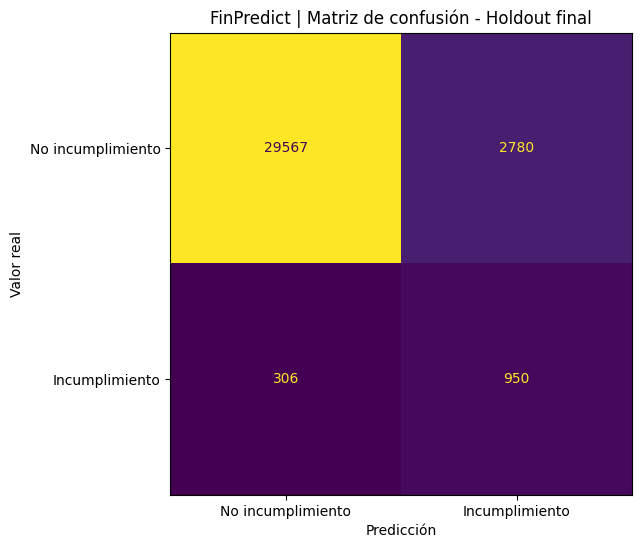

Detalle numérico:
Verdaderos negativos (TN): 29567
Falsos positivos (FP): 2780
Falsos negativos (FN): 306
Verdaderos positivos (TP): 950


In [22]:
# ============================================================
# FINPREDICT | ACTIVIDAD 6
# MATRIZ DE CONFUSIÓN FINAL - VISUAL
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm_final = confusion_matrix(
    y_holdout,
    y_pred_holdout
)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=["No incumplimiento", "Incumplimiento"]
)

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

plt.title("FinPredict | Matriz de confusión - Holdout final")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.grid(False)
plt.show()

print("Detalle numérico:")
print(f"Verdaderos negativos (TN): {cm_final[0, 0]}")
print(f"Falsos positivos (FP): {cm_final[0, 1]}")
print(f"Falsos negativos (FN): {cm_final[1, 0]}")
print(f"Verdaderos positivos (TP): {cm_final[1, 1]}")

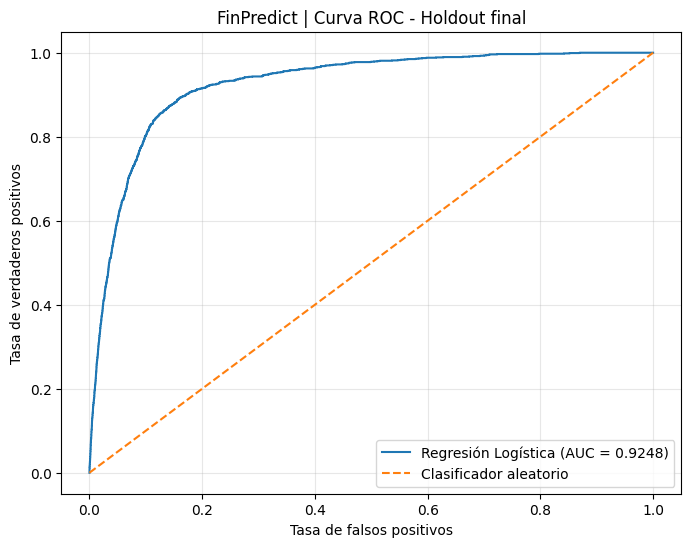

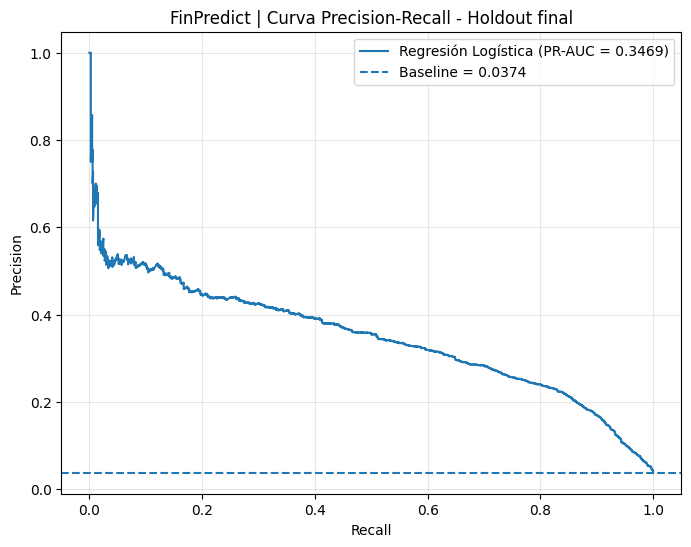

FINPREDICT | CURVAS FINALES
------------------------------------------------------------
ROC-AUC: 0.9248
PR-AUC: 0.3469
Baseline PR-AUC: 0.0374


In [17]:
# ============================================================
# FINPREDICT | ACTIVIDAD 6
# 14. CURVAS ROC Y PRECISION-RECALL EN HOLDOUT
# ============================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

# ------------------------------------------------------------
# 1. Curva ROC
# ------------------------------------------------------------

fpr, tpr, _ = roc_curve(
    y_holdout,
    y_prob_holdout
)

roc_auc_final = roc_auc_score(
    y_holdout,
    y_prob_holdout
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Regresión Logística (AUC = {roc_auc_final:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Clasificador aleatorio"
)

plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("FinPredict | Curva ROC - Holdout final")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ------------------------------------------------------------
# 2. Curva Precision-Recall
# ------------------------------------------------------------

precision_curve, recall_curve, _ = precision_recall_curve(
    y_holdout,
    y_prob_holdout
)

pr_auc_final = average_precision_score(
    y_holdout,
    y_prob_holdout
)

prevalencia_holdout = (
    y_holdout.mean()
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"Regresión Logística (PR-AUC = {pr_auc_final:.4f})"
)

plt.axhline(
    prevalencia_holdout,
    linestyle="--",
    label=f"Baseline = {prevalencia_holdout:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("FinPredict | Curva Precision-Recall - Holdout final")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("FINPREDICT | CURVAS FINALES")
print("-" * 60)
print(f"ROC-AUC: {roc_auc_final:.4f}")
print(f"PR-AUC: {pr_auc_final:.4f}")
print(f"Baseline PR-AUC: {prevalencia_holdout:.4f}")

In [18]:
# ============================================================
# FINPREDICT | ACTIVIDAD 6
# 15. SIMULACIÓN DE PRUEBA A/B OPERATIVA
# ============================================================

from scipy.stats import chi2_contingency

rng_ab = np.random.default_rng(SEED)

# ------------------------------------------------------------
# 1. Base de créditos priorizados por FinPredict
# ------------------------------------------------------------

df_ab = df_evaluacion[
    [
        "id_credito",
        COLUMNA_TARGET
    ]
].copy()

df_ab["probabilidad_riesgo"] = (
    y_prob_holdout
)

df_ab["priorizado"] = (
    df_ab["probabilidad_riesgo"]
    >= THRESHOLD_OPERATIVO
)

df_ab = (
    df_ab.loc[
        df_ab["priorizado"]
    ]
    .copy()
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. Asignación aleatoria A/B
# ------------------------------------------------------------

df_ab["grupo"] = rng_ab.choice(
    ["CONTROL", "FINPREDICT"],
    size=len(df_ab),
    replace=True
)

# ------------------------------------------------------------
# 3. Resultado base observado
# ------------------------------------------------------------

df_ab["incumplimiento_observado"] = (
    df_ab[COLUMNA_TARGET]
)

# ------------------------------------------------------------
# 4. Simulación de intervención preventiva
# ------------------------------------------------------------

# Supuesto académico:
# la intervención preventiva logra evitar
# el 15% de los incumplimientos del grupo tratado.

EFECTIVIDAD_INTERVENCION = 0.15

df_ab["incumplimiento_post"] = (
    df_ab["incumplimiento_observado"]
)

mask_tratamiento = (
    (df_ab["grupo"] == "FINPREDICT")
    & (df_ab["incumplimiento_observado"] == 1)
)

evitados = (
    rng_ab.random(
        mask_tratamiento.sum()
    )
    < EFECTIVIDAD_INTERVENCION
)

indices_tratamiento = (
    df_ab.index[
        mask_tratamiento
    ]
)

df_ab.loc[
    indices_tratamiento[evitados],
    "incumplimiento_post"
] = 0

# ------------------------------------------------------------
# 5. Resultados por grupo
# ------------------------------------------------------------

resumen_ab = (
    df_ab
    .groupby("grupo")
    .agg(
        creditos=("id_credito", "count"),
        incumplimientos=(
            "incumplimiento_post",
            "sum"
        ),
        tasa_incumplimiento=(
            "incumplimiento_post",
            "mean"
        )
    )
    .reset_index()
)

resumen_ab[
    "tasa_incumplimiento_%"
] = (
    resumen_ab[
        "tasa_incumplimiento"
    ] * 100
).round(2)

# ------------------------------------------------------------
# 6. Prueba Chi-cuadrada
# ------------------------------------------------------------

tabla_ab = pd.crosstab(
    df_ab["grupo"],
    df_ab["incumplimiento_post"]
)

chi2, p_value, dof, esperados = (
    chi2_contingency(
        tabla_ab
    )
)

# ------------------------------------------------------------
# 7. Resultados
# ------------------------------------------------------------

print("FINPREDICT | SIMULACIÓN A/B")
print("-" * 75)

print(
    f"Créditos priorizados: "
    f"{len(df_ab):,}"
)

print(
    f"Efectividad simulada de intervención: "
    f"{EFECTIVIDAD_INTERVENCION:.0%}"
)

print("\nResultados por grupo:")
display(
    resumen_ab[
        [
            "grupo",
            "creditos",
            "incumplimientos",
            "tasa_incumplimiento_%"
        ]
    ]
)

print("\nPrueba estadística:")
print(
    f"Chi-cuadrada: {chi2:.4f}"
)

print(
    f"p-value: {p_value:.4f}"
)

print("-" * 75)
print(
    "Nota: experimento simulado con fines académicos; "
    "no representa una intervención real."
)

FINPREDICT | SIMULACIÓN A/B
---------------------------------------------------------------------------
Créditos priorizados: 3,730
Efectividad simulada de intervención: 15%

Resultados por grupo:


,grupo,creditos,incumplimientos,tasa_incumplimiento_%
0,CONTROL,1863,486,26.09
1,FINPREDICT,1867,385,20.62



Prueba estadística:
Chi-cuadrada: 15.2599
p-value: 0.0001
---------------------------------------------------------------------------
Nota: experimento simulado con fines académicos; no representa una intervención real.


In [19]:
# ============================================================
# FINPREDICT | ACTIVIDAD 6
# 16. IMPACTO OPERATIVO DE LA SIMULACIÓN A/B
# ============================================================

# ------------------------------------------------------------
# 1. Recuperar tasas de los grupos
# ------------------------------------------------------------

tasa_control = resumen_ab.loc[
    resumen_ab["grupo"] == "CONTROL",
    "tasa_incumplimiento"
].iloc[0]

tasa_finpredict = resumen_ab.loc[
    resumen_ab["grupo"] == "FINPREDICT",
    "tasa_incumplimiento"
].iloc[0]

# ------------------------------------------------------------
# 2. Medidas de impacto
# ------------------------------------------------------------

reduccion_absoluta = (
    tasa_control - tasa_finpredict
)

reduccion_relativa = (
    reduccion_absoluta / tasa_control
)

# Número necesario a intervenir
nnt = (
    1 / reduccion_absoluta
    if reduccion_absoluta > 0
    else np.nan
)

# Incumplimientos esperados en el grupo tratado
# si hubiera tenido la misma tasa que el control
n_finpredict = int(
    resumen_ab.loc[
        resumen_ab["grupo"] == "FINPREDICT",
        "creditos"
    ].iloc[0]
)

incumplimientos_esperados_sin_intervencion = (
    n_finpredict * tasa_control
)

incumplimientos_observados_simulados = int(
    resumen_ab.loc[
        resumen_ab["grupo"] == "FINPREDICT",
        "incumplimientos"
    ].iloc[0]
)

incumplimientos_evitar_estimados = (
    incumplimientos_esperados_sin_intervencion
    - incumplimientos_observados_simulados
)

# ------------------------------------------------------------
# 3. Resumen ejecutivo
# ------------------------------------------------------------

impacto_negocio = pd.DataFrame({
    "indicador": [
        "Tasa de incumplimiento - Control",
        "Tasa de incumplimiento - FinPredict",
        "Reducción absoluta",
        "Reducción relativa",
        "Número necesario a intervenir (NNT)",
        "Incumplimientos evitados estimados"
    ],
    "resultado": [
        f"{tasa_control:.2%}",
        f"{tasa_finpredict:.2%}",
        f"{reduccion_absoluta:.2%}",
        f"{reduccion_relativa:.2%}",
        f"{nnt:.1f}",
        f"{incumplimientos_evitar_estimados:.1f}"
    ]
})

print("FINPREDICT | IMPACTO OPERATIVO SIMULADO")
print("-" * 75)

display(impacto_negocio)

print("-" * 75)

print(
    "Interpretación: los resultados corresponden a una "
    "simulación académica y deben validarse mediante un "
    "experimento A/B real antes de atribuir impacto causal."
)

FINPREDICT | IMPACTO OPERATIVO SIMULADO
---------------------------------------------------------------------------


,indicador,resultado
0,Tasa de incumplimiento - Control,26.09%
1,Tasa de incumplimiento - FinPredict,20.62%
2,Reducción absoluta,5.47%
3,Reducción relativa,20.95%
4,Número necesario a intervenir (NNT),18.3
5,Incumplimientos evitados estimados,102.0


---------------------------------------------------------------------------
Interpretación: los resultados corresponden a una simulación académica y deben validarse mediante un experimento A/B real antes de atribuir impacto causal.


In [20]:
# ============================================================
# FINPREDICT | ACTIVIDAD 6
# 17. RESUMEN FINAL DE RESULTADOS
# ============================================================

resumen_final = pd.DataFrame({
    "bloque": [
        "Baseline",
        "Modelo seleccionado",
        "Validación cruzada",
        "Comparación estadística",
        "Threshold",
        "Holdout final",
        "Holdout final",
        "Holdout final",
        "Holdout final",
        "Holdout final",
        "Impacto operativo simulado",
        "Impacto operativo simulado"
    ],

    "indicador": [
        "Accuracy DummyClassifier",
        "Modelo",
        "PR-AUC OOF",
        "Diferencia PR-AUC Logística - RF",
        "Threshold operativo",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "PR-AUC",
        "Reducción relativa de incumplimiento",
        "NNT"
    ],

    "resultado": [
        "96.16%",
        "Regresión Logística",
        "0.3386",
        "0.0104 (IC95%: 0.0039 a 0.0174)",
        "0.75",
        "25.47%",
        "75.64%",
        "38.11%",
        "0.9248",
        "0.3469",
        "20.95%",
        "18.3"
    ]
})

print("FINPREDICT | RESUMEN EJECUTIVO")
print("-" * 90)

display(resumen_final)

FINPREDICT | RESUMEN EJECUTIVO
------------------------------------------------------------------------------------------


,bloque,indicador,resultado
0,Baseline,Accuracy DummyClassifier,96.16%
1,Modelo seleccionado,Modelo,Regresión Logística
2,Validación cruzada,PR-AUC OOF,0.3386
3,Comparación estadística,Diferencia PR-AUC Logística - RF,0.0104 (IC95%: 0.0039 a 0.0174)
4,Threshold,Threshold operativo,0.75
5,Holdout final,Precision,25.47%
6,Holdout final,Recall,75.64%
7,Holdout final,F1,38.11%
8,Holdout final,ROC-AUC,0.9248
9,Holdout final,PR-AUC,0.3469


## Conclusiones

La evaluación realizada muestra que el uso exclusivo de accuracy no es adecuado
para FinPredict debido al desbalance de clases. El DummyClassifier alcanzó una
accuracy de 96.16%, pero no identificó ningún incumplimiento, con recall y F1
iguales a cero.

La Regresión Logística y Random Forest mostraron un desempeño sustancialmente
superior al baseline. Durante la validación cruzada temporal ambos modelos
presentaron una capacidad de discriminación similar en ROC-AUC; sin embargo,
la Regresión Logística obtuvo un PR-AUC superior.

El análisis bootstrap agrupado por crédito mostró una diferencia media de
PR-AUC de 0.0104 a favor de la Regresión Logística, con un intervalo de confianza
del 95% entre 0.0039 y 0.0174. Para ROC-AUC, el intervalo incluyó cero, por lo
que no se observó una diferencia concluyente entre los modelos en esa métrica.

Considerando el desbalance de la clase objetivo, el desempeño predictivo,
la estabilidad temporal y la interpretabilidad, se seleccionó la
Regresión Logística como modelo final.

El threshold operativo se ajustó de 0.50 a 0.75. Esta decisión reduce la carga
operativa al priorizar aproximadamente 11% de la cartera, manteniendo una
capacidad de detección cercana al 75% de los incumplimientos futuros.

En el holdout temporal final, el modelo obtuvo:

- Precision: 25.47%
- Recall: 75.64%
- F1-score: 38.11%
- Specificity: 91.41%
- ROC-AUC: 0.9248
- PR-AUC: 0.3469

La matriz de confusión mostró 950 verdaderos positivos, 306 falsos negativos,
2,780 falsos positivos y 29,567 verdaderos negativos.

Finalmente, se desarrolló una simulación académica de prueba A/B para ilustrar
cómo podría evaluarse una intervención preventiva en producción. Bajo un supuesto
de efectividad del 15%, la tasa de incumplimiento simulada se redujo de 26.09%
a 20.62%, equivalente a una reducción relativa de 20.95% y un NNT de 18.3.

Estos resultados no representan evidencia causal real, ya que la prueba A/B fue
simulada. En una implementación productiva sería necesario validar el impacto
mediante un experimento controlado con asignación aleatoria.

En conjunto, FinPredict demuestra que un modelo relativamente simple e
interpretable puede generar valor al priorizar de forma preventiva una fracción
reducida de la cartera y concentrar los esfuerzos operativos en créditos con
mayor riesgo de incumplimiento.

In [21]:
  # ============================================================
# FINPREDICT | ACTIVIDAD 6
# 18. EXPORTACIÓN DE RESULTADOS
# ============================================================

from pathlib import Path

# ------------------------------------------------------------
# 1. Crear carpeta local de resultados
# ------------------------------------------------------------

RUTA_RESULTADOS = Path(
    "/content/resultados_actividad6"
)

RUTA_RESULTADOS.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. Exportar tablas principales
# ------------------------------------------------------------

comparacion_modelos.to_csv(
    RUTA_RESULTADOS / "comparacion_modelos.csv",
    index=False
)

df_resultados_cv.to_csv(
    RUTA_RESULTADOS / "validacion_cruzada_temporal.csv",
    index=False
)

resumen_estadistico.to_csv(
    RUTA_RESULTADOS / "comparacion_estadistica_bootstrap.csv",
    index=False
)

df_threshold.to_csv(
    RUTA_RESULTADOS / "analisis_threshold.csv",
    index=False
)

metricas_holdout.to_csv(
    RUTA_RESULTADOS / "metricas_holdout_final.csv",
    index=False
)

resumen_ab.to_csv(
    RUTA_RESULTADOS / "simulacion_ab.csv",
    index=False
)

impacto_negocio.to_csv(
    RUTA_RESULTADOS / "impacto_operativo_simulado.csv",
    index=False
)

resumen_final.to_csv(
    RUTA_RESULTADOS / "resumen_ejecutivo.csv",
    index=False
)

# ------------------------------------------------------------
# 3. Exportar predicciones finales
# ------------------------------------------------------------

df_predicciones_holdout = df_evaluacion[
    [
        "id_credito",
        "fecha_corte",
        COLUMNA_TARGET
    ]
].copy()

df_predicciones_holdout[
    "probabilidad_riesgo"
] = y_prob_holdout

df_predicciones_holdout[
    "prediccion_threshold_075"
] = y_pred_holdout

df_predicciones_holdout.to_csv(
    RUTA_RESULTADOS / "predicciones_holdout_final.csv",
    index=False
)

# ------------------------------------------------------------
# 4. Verificación
# ------------------------------------------------------------

print("FINPREDICT | RESULTADOS EXPORTADOS")
print("-" * 75)

for archivo in sorted(
    RUTA_RESULTADOS.glob("*.csv")
):
    print(f"✓ {archivo.name}")

print("-" * 75)

print(
    f"Ruta local: {RUTA_RESULTADOS}"
)

FINPREDICT | RESULTADOS EXPORTADOS
---------------------------------------------------------------------------
✓ analisis_threshold.csv
✓ comparacion_estadistica_bootstrap.csv
✓ comparacion_modelos.csv
✓ impacto_operativo_simulado.csv
✓ metricas_holdout_final.csv
✓ predicciones_holdout_final.csv
✓ resumen_ejecutivo.csv
✓ simulacion_ab.csv
✓ validacion_cruzada_temporal.csv
---------------------------------------------------------------------------
Ruta local: /content/resultados_actividad6
